In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import scipy.stats as stats

ruta = r"C:\Users\Josue Santana Robled\Downloads"

In [2]:
fact     = pd.read_csv(os.path.join(ruta, "FACT_SALES.csv"))
product  = pd.read_csv(os.path.join(ruta, "DIM_PRODUCT.csv"), encoding="cp1252", dtype={"ITEM": str})
calendar = pd.read_csv(os.path.join(ruta, "DIM_CALENDAR.csv"))
segment  = pd.read_csv(os.path.join(ruta, "DIM_SEGMENT.csv"))
category = pd.read_csv(os.path.join(ruta, "DIM_CATEGORY.csv"))

print("FACT_SALES:", fact.shape)
print("DIM_PRODUCT:", product.shape)
print("DIM_CALENDAR:", calendar.shape)
print("DIM_SEGMENT:", segment.shape)
print("DIM_CATEGORY:", category.shape)

FACT_SALES: (122002, 6)
DIM_PRODUCT: (505, 9)
DIM_CALENDAR: (156, 5)
DIM_SEGMENT: (53, 6)
DIM_CATEGORY: (5, 2)


In [3]:
fact["ITEM_CODE"]= fact["ITEM_CODE"].astype(str).str.strip()
product["ITEM"]= product["ITEM"].astype(str).str.strip()
fact["WEEK"]= fact["WEEK"].astype(str).str.strip()
calendar["WEEK"] = calendar["WEEK"].astype(str).str.strip()
calendar["DATE"]= pd.to_datetime(calendar["DATE"], format="%d/%m/%Y", errors="coerce")
fact["TOTAL_UNIT_SALES"]= pd.to_numeric(fact["TOTAL_UNIT_SALES"],  errors="coerce")
fact["TOTAL_VALUE_SALES"] = pd.to_numeric(fact["TOTAL_VALUE_SALES"], errors="coerce")

semanas_fact = set(fact["WEEK"].unique())
semanas_cal  = set(calendar["WEEK"].unique())

print("Semanas en FACT:", len(semanas_fact))
print("Semanas en CALENDAR:", len(semanas_cal))
print("Semanas en FACT sin calendario:", len(semanas_fact - semanas_cal))
print("Duplicados WEEK en calendario:", calendar["WEEK"].duplicated().sum())

fact_dates = fact.merge(calendar[["WEEK","DATE"]], on="WEEK", how="left")
print("Rango fact (vía calendario):", fact_dates["DATE"].min().date(), "→", fact_dates["DATE"].max().date())
print("Filas fact sin fecha:", fact_dates["DATE"].isna().sum())

Semanas en FACT: 80
Semanas en CALENDAR: 156
Semanas en FACT sin calendario: 0
Duplicados WEEK en calendario: 0
Rango fact (vía calendario): 2022-01-09 → 2023-07-17
Filas fact sin fecha: 0


In [4]:
product = product[product["ITEM"].notna()].copy()
product = product[product["ITEM"].str.upper().str.strip() != "N/A"].copy()

print("Items duplicados en DIM_PRODUCT:", product.duplicated(subset=["ITEM"], keep=False).sum())
product = product.drop_duplicates(subset=["ITEM"], keep="first")
print("Productos únicos tras limpieza:", len(product))

Items duplicados en DIM_PRODUCT: 2
Productos únicos tras limpieza: 504


In [5]:
df = fact.merge(product[["ITEM","MANUFACTURER","BRAND","ITEM_DESCRIPTION","CATEGORY","FORMAT","ATTR1","ATTR2","ATTR3"]],left_on="ITEM_CODE", right_on="ITEM", how="left")
df = df.merge(calendar[["WEEK","YEAR","MONTH","WEEK_NUMBER","DATE"]],on="WEEK", how="left")

print("Consolidado:", df.shape)
print("Sin match de producto:", df["BRAND"].isna().sum())
print("Sin match de fecha:",    df["DATE"].isna().sum())
print("Filas duplicadas exactas:", df.duplicated().sum())

Consolidado: (122002, 19)
Sin match de producto: 0
Sin match de fecha: 0
Filas duplicadas exactas: 0


In [6]:
df["BRAND"] = df["BRAND"].astype(str).str.upper().str.strip()
df["BRAND_GRUPO"] = np.where(df["BRAND"].str.contains("VANISH"), "VANISH",np.where(df["BRAND"].str.contains("LYSOL"),  "LYSOL", df["BRAND"]))

marcas_objetivo = ["VANISH", "LYSOL"]
df_obj = df[df["BRAND_GRUPO"].isin(marcas_objetivo)].copy()

print(df_obj.groupby("BRAND_GRUPO").agg(
    n_filas    = ("ITEM_CODE","size"),
    n_items    = ("ITEM_CODE","nunique"),
    n_semanas  = ("WEEK","nunique"),
    n_regiones = ("REGION","nunique"),
    fecha_min  = ("DATE","min"),
    fecha_max  = ("DATE","max")
))

             n_filas  n_items  n_semanas  n_regiones  fecha_min  fecha_max
BRAND_GRUPO                                                               
LYSOL           3449        8         80           7 2022-01-09 2023-07-17
VANISH         28377       77         80           7 2022-01-09 2023-07-17


In [7]:
serie = (df_obj.groupby(["BRAND_GRUPO","WEEK","YEAR","WEEK_NUMBER","DATE"], as_index=False)
         .agg(TOTAL_UNIT_SALES  = ("TOTAL_UNIT_SALES","sum"),
              TOTAL_VALUE_SALES = ("TOTAL_VALUE_SALES","sum"),
              N_ITEMS           = ("ITEM_CODE","nunique"),
              N_REGIONES        = ("REGION","nunique"))
         .sort_values(["BRAND_GRUPO","DATE"])
         .reset_index(drop=True))

for marca in marcas_objetivo:
    s = serie[serie["BRAND_GRUPO"] == marca]
    if len(s) == 0:
        print(f"{marca}: sin datos"); continue
    rango_teorico = pd.date_range(s["DATE"].min(), s["DATE"].max(), freq="7D")
    print(f"{marca}: {len(s)} semanas observadas, ~{len(rango_teorico)} esperadas | "
          f"{s['DATE'].min().date()} → {s['DATE'].max().date()}")

serie.head(10)

VANISH: 80 semanas observadas, ~80 esperadas | 2022-01-09 → 2023-07-17
LYSOL: 80 semanas observadas, ~80 esperadas | 2022-01-09 → 2023-07-17


,BRAND_GRUPO,WEEK,YEAR,WEEK_NUMBER,DATE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,N_ITEMS,N_REGIONES
0,LYSOL,01-22,2022,1,2022-01-09,12.958,1748.678,5,7
1,LYSOL,02-22,2022,2,2022-01-16,17.242,2248.498,5,7
2,LYSOL,03-22,2022,3,2022-01-23,16.956,2303.522,5,7
3,LYSOL,04-22,2022,4,2022-01-30,16.402,2263.808,6,7
4,LYSOL,05-22,2022,5,2022-02-06,11.828,1731.716,6,7
5,LYSOL,06-22,2022,6,2022-02-13,9.150,1382.172,5,7
6,LYSOL,07-22,2022,7,2022-02-20,7.986,1144.737,5,7
7,LYSOL,08-22,2022,8,2022-02-27,6.934,997.070,5,7
8,LYSOL,09-22,2022,9,2022-03-06,6.474,919.083,6,7
9,LYSOL,10-22,2022,10,2022-03-13,5.542,797.707,5,7


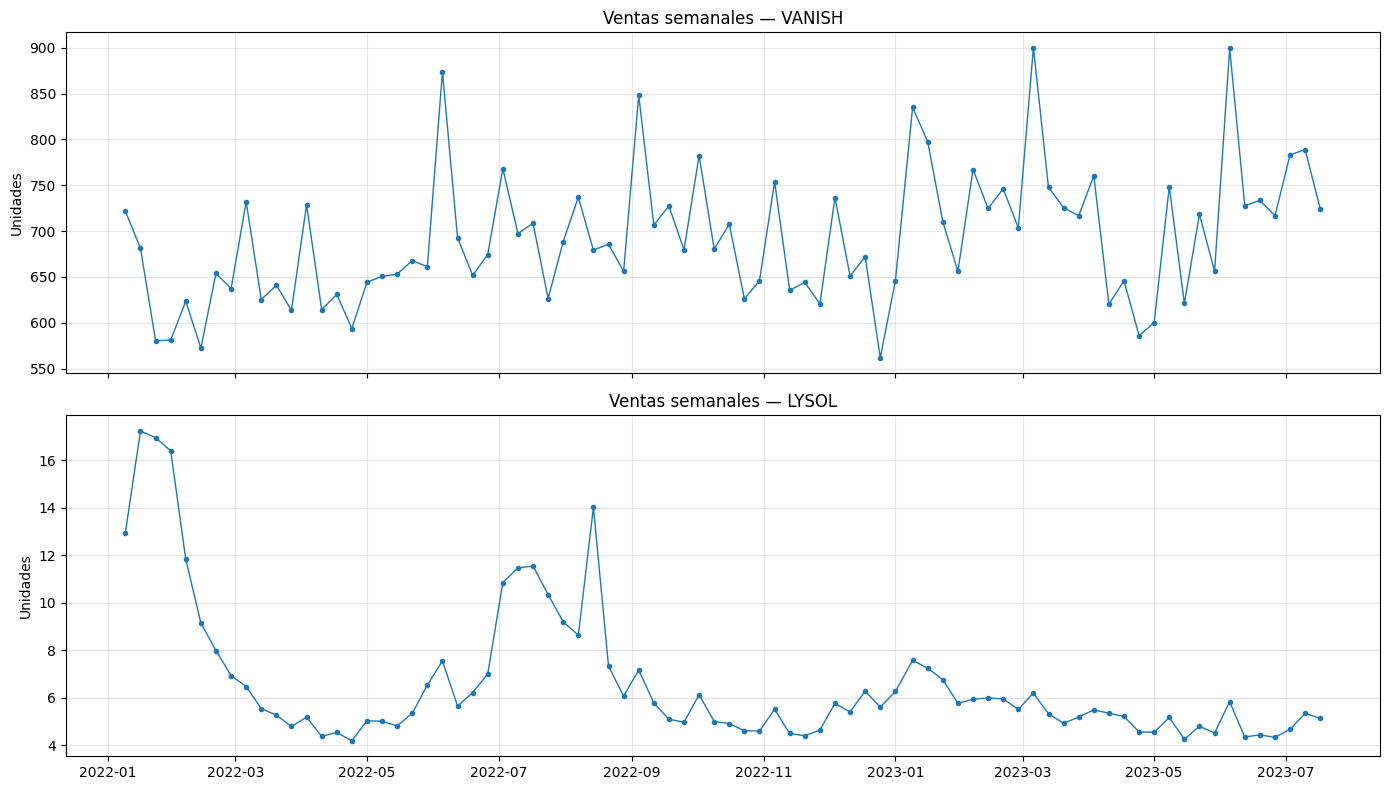

             count        mean        std      min       25%       50%  \
BRAND_GRUPO                                                              
LYSOL         80.0    6.618625   2.921925    4.188    4.9235    5.5280   
VANISH        80.0  691.661800  72.720300  561.844  643.2905  680.7265   

                   75%      max  
BRAND_GRUPO                      
LYSOL          6.95100   17.242  
VANISH       729.57825  899.960  


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, marca in zip(axes, marcas_objetivo):
    s = serie[serie["BRAND_GRUPO"] == marca]
    if len(s) == 0:
        ax.set_title(f"{marca}: sin datos"); continue
    ax.plot(s["DATE"], s["TOTAL_UNIT_SALES"], marker="o", ms=3, lw=1)
    ax.set_title(f"Ventas semanales — {marca}")
    ax.set_ylabel("Unidades"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(serie.groupby("BRAND_GRUPO")["TOTAL_UNIT_SALES"].describe())

In [9]:
series_modelo = {}

for marca in marcas_objetivo:
    s = (serie[serie["BRAND_GRUPO"] == marca].set_index("DATE")["TOTAL_UNIT_SALES"].sort_index())
    if len(s) == 0:
        continue

    s = s.asfreq("7D")
    ultimo_valido = s.last_valid_index()
    s = s.loc[:ultimo_valido]

    n_huecos_internos = s.isna().sum()
    if n_huecos_internos:
        print(f"{marca}: {n_huecos_internos} huecos internos → interpolando")
        s = s.interpolate(method="time").ffill().bfill()

    series_modelo[marca] = s
    print(f"{marca}: {len(s)} semanas reales, "
          f"{s.index.min().date()} → {s.index.max().date()}, "
          f"media={s.mean():.2f}, std={s.std():.2f}")

for marca, s in series_modelo.items():
    print(f"\n{marca} — tail:")
    print(s.tail(3))

VANISH: 52 semanas reales, 2022-01-09 → 2023-01-01, media=672.54, std=62.60
LYSOL: 52 semanas reales, 2022-01-09 → 2023-01-01, media=7.29, std=3.39

VANISH — tail:
DATE
2022-12-18    672.139
2022-12-25    561.844
2023-01-01    645.830
Freq: 7D, Name: TOTAL_UNIT_SALES, dtype: float64

LYSOL — tail:
DATE
2022-12-18    6.282
2022-12-25    5.605
2023-01-01    6.266
Freq: 7D, Name: TOTAL_UNIT_SALES, dtype: float64


In [10]:
def test_estacionariedad(s, nombre):
    print(f"\n {nombre} ")
    adf_p = adfuller(s.dropna())[1]
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        kpss_p = kpss(s.dropna(), regression='c', nlags='auto')[1]
    print(f"ADF  p-value = {adf_p:.4f}  → {'estacionaria' if adf_p < 0.05 else 'NO estacionaria'}")
    print(f"KPSS p-value = {kpss_p:.4f}  → {'estacionaria' if kpss_p >= 0.05 else 'NO estacionaria'}")
    adf_p_d1 = adfuller(s.diff().dropna())[1]
    print(f"ADF 1a dif  p = {adf_p_d1:.4f} → {'estacionaria' if adf_p_d1 < 0.05 else 'NO estacionaria'}")

for marca, s in series_modelo.items():
    test_estacionariedad(s, marca)


 VANISH 
ADF  p-value = 0.7864  → NO estacionaria
KPSS p-value = 0.0988  → estacionaria
ADF 1a dif  p = 0.0474 → estacionaria

 LYSOL 
ADF  p-value = 0.1635  → NO estacionaria
KPSS p-value = 0.1000  → estacionaria
ADF 1a dif  p = 0.0000 → estacionaria


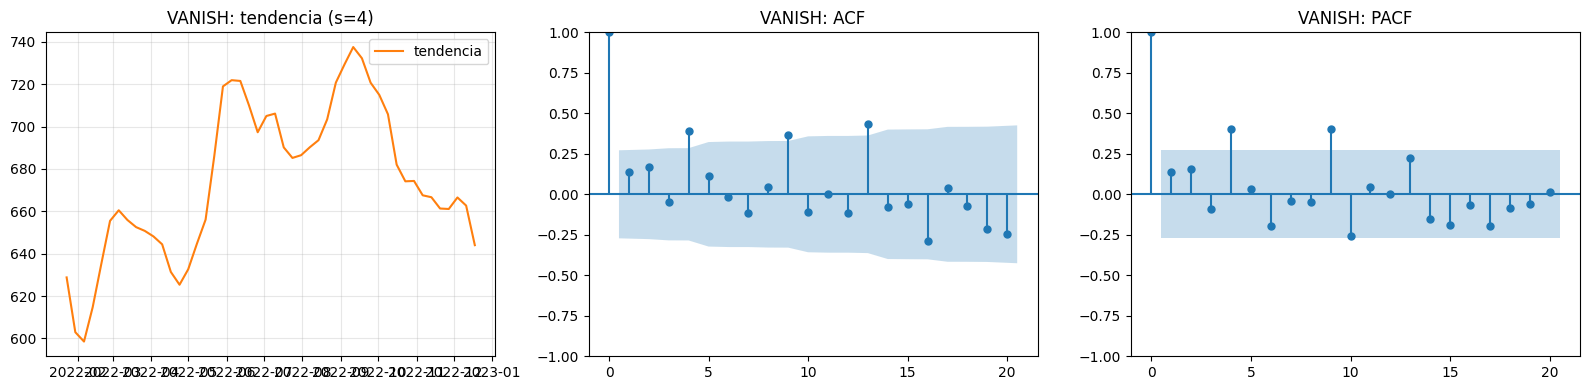

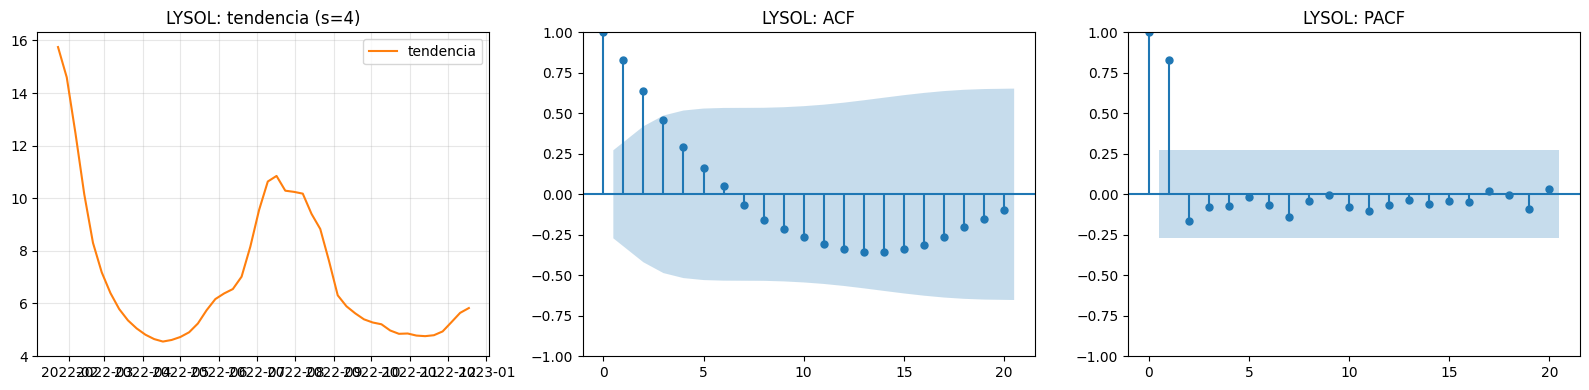

In [11]:
for marca, s in series_modelo.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    dec = seasonal_decompose(s, model="additive", period=4)
    axes[0].plot(
        dec.trend, label="tendencia", color="C1")
    axes[0].set_title(f"{marca}: tendencia (s=4)")
    axes[0].legend(); axes[0].grid(alpha=.3)
    plot_acf(s, lags=20, ax=axes[1], title=f"{marca}: ACF")
    plot_pacf(s, lags=20, ax=axes[2], title=f"{marca}: PACF", method='ywm')
    plt.tight_layout(); 
    plt.show()

In [12]:
N_TEST = 10  

def construir_features(idx):
    df_feat = pd.DataFrame(index=idx)
    df_feat["trend"]    = np.arange(len(idx))
    df_feat["mes"]      = idx.month
    df_feat["sem_anio"] = idx.isocalendar().week.astype(int).values
    for m in range(2, 13):
        df_feat[f"mes_{m}"] = (idx.month == m).astype(int)
    return df_feat

resultados = {}

for marca, s in series_modelo.items():
    train = s.iloc[:-N_TEST]
    test  = s.iloc[-N_TEST:]
    X_train = construir_features(train.index)
    X_test  = construir_features(test.index)

    modelo = LinearRegression().fit(X_train, train)
    pred   = pd.Series(modelo.predict(X_test), index=test.index)

    mae  = mean_absolute_error(test, pred)
    rmse = np.sqrt(mean_squared_error(test, pred))
    mape = np.mean(np.abs((test - pred) / test.clip(lower=1e-6))) * 100
    mse = mean_squared_error(test, pred)

    trend_slope = np.polyfit(np.arange(len(train)), train.values, 1)[0]
    baseline    = train.iloc[-1] + trend_slope * np.arange(1, N_TEST + 1)
    mae_b  = mean_absolute_error(test, baseline)
    rmse_b = np.sqrt(mean_squared_error(test, baseline))
    mape_b = np.mean(np.abs((test - baseline) / test.clip(lower=1e-6))) * 100

    resultados[marca] = {
        "modelo": modelo, "pred": pred, "test": test,
        "mae": mae, "rmse": rmse, "mape": mape,
        "mae_b": mae_b, "rmse_b": rmse_b, "mape_b": mape_b,
    }
    print(f"\n{marca} ")
    print(f"Regresión - MAE ={mae:7.2f}  RMSE ={rmse:7.2f}  MAPE ={mape:6.2f}%")
    print(f"Baseline - MAE ={mae_b:7.2f}  RMSE ={rmse_b:7.2f}  MAPE ={mape_b:6.2f}%")


VANISH 
Regresión - MAE = 635.64  RMSE = 638.76  MAPE = 97.76%
Baseline - MAE =  39.05  RMSE =  57.70  MAPE =  5.78%

LYSOL 
Regresión - MAE =   3.20  RMSE =   3.72  MAPE = 65.36%
Baseline - MAE =   1.29  RMSE =   1.59  MAPE = 22.47%


In [13]:
def buscar_sarima(serie, s=4, max_p=2, max_d=2, max_q=2,
                  max_P=1, max_D=1, max_Q=1):
    best_aic = np.inf
    best_model = None
    best_order = None
    best_seasonal = None

    for p in range(max_p + 1):
        for d in range(max_d + 1):
            for q in range(max_q + 1):
                for P in range(max_P + 1):
                    for D in range(max_D + 1):
                        for Q in range(max_Q + 1):
                            if p == d == q == P == D == Q == 0:
                                continue
                            try:
                                with warnings.catch_warnings():
                                    warnings.filterwarnings("ignore")
                                    mod = SARIMAX(
                                        serie,
                                        order=(p, d, q),
                                        seasonal_order=(P, D, Q, s),
                                        enforce_stationarity=False,
                                        enforce_invertibility=False,
                                    ).fit(disp=False)
                                if np.isfinite(mod.aic) and mod.aic < best_aic:
                                    best_aic = mod.aic
                                    best_model = mod
                                    best_order = (p, d, q)
                                    best_seasonal = (P, D, Q, s)
                            except Exception:
                                continue
    return best_model, best_order, best_seasonal, best_aic


modelos_sarima = {}
print("Búsqueda SARIMA\n")

for marca, s in series_modelo.items():
    print(f"\n--- {marca} ---")
    mod, order, seasonal, aic = buscar_sarima(
        s, s=4, max_p=2, max_d=1, max_q=2, max_P=1, max_D=1, max_Q=1
    )
    print(f"Mejor SARIMA: order={order}, seasonal={seasonal}, AIC={aic:.2f}")
    modelos_sarima[marca] = {
        "modelo": mod, "order": order, "seasonal": seasonal, "aic": aic,
    }

Búsqueda SARIMA


--- VANISH ---
Mejor SARIMA: order=(0, 1, 2), seasonal=(0, 1, 1, 4), AIC=457.21

--- LYSOL ---
Mejor SARIMA: order=(1, 0, 2), seasonal=(0, 1, 1, 4), AIC=168.42


In [14]:
print("\n Validación Sarima \n")

for marca, s in series_modelo.items():
    train = s.iloc[:-N_TEST]
    test  = s.iloc[-N_TEST:]

    p, d, q = modelos_sarima[marca]["order"]
    P, D, Q, s_per = modelos_sarima[marca]["seasonal"]

    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        mod_train = SARIMAX(train, order=(p, d, q), seasonal_order=(P, D, Q, s_per),enforce_stationarity=False, enforce_invertibility=False,).fit(disp=False)

    pred_sarima = mod_train.forecast(steps=N_TEST)
    pred_sarima.index = test.index

    mae_s  = mean_absolute_error(test, pred_sarima)
    rmse_s = np.sqrt(mean_squared_error(test, pred_sarima))
    mape_s = np.mean(np.abs((test - pred_sarima) / test.clip(lower=1e-6))) * 100
    mse = mean_squared_error(test, pred)

    print(f"{marca}:")
    print(f"  SARIMA  - MAE={mae_s:7.2f}  RMSE={rmse_s:7.2f}  MAPE={mape_s:6.2f}%")
    print(f"  Regresión - MAE={resultados[marca]['mae']:7.2f}  MAPE={resultados[marca]['mape']:6.2f}%")
    print(f"  Baseline  - MAE={resultados[marca]['mae_b']:7.2f}  MAPE={resultados[marca]['mape_b']:6.2f}%")

    resultados[marca].update({
        "order_sarima": (p, d, q),
        "seasonal_sarima": (P, D, Q, s_per),
        "mae_sarima": mae_s,
        "rmse_sarima": rmse_s,
        "mape_sarima": mape_s,
        "pred_sarima": pred_sarima,
        "mse": mse,
    })


 Validación Sarima 

VANISH:
  SARIMA  - MAE=  97.15  RMSE= 127.21  MAPE= 15.64%
  Regresión - MAE= 635.64  MAPE= 97.76%
  Baseline  - MAE=  39.05  MAPE=  5.78%
LYSOL:
  SARIMA  - MAE=   0.77  RMSE=   0.84  MAPE= 15.36%
  Regresión - MAE=   3.20  MAPE= 65.36%
  Baseline  - MAE=   1.29  MAPE= 22.47%


In [15]:
def evaluar_variantes(serie_ts, variantes, n_test=10):
    train = serie_ts.iloc[:-n_test]
    test  = serie_ts.iloc[-n_test:]

    filas = []
    for v in variantes:
        try:
            with warnings.catch_warnings():
                warnings.filterwarnings("ignore")
                m_full = SARIMAX(serie_ts, order=v["order"],seasonal_order=v["seasonal"],enforce_stationarity=False,enforce_invertibility=False).fit(disp=False)
                m_train = SARIMAX(train, order=v["order"],seasonal_order=v["seasonal"],enforce_stationarity=False,enforce_invertibility=False).fit(disp=False)

            lb_p = acorr_ljungbox(m_full.resid.dropna(), lags=[10], return_df=True)["lb_pvalue"].iloc[0]
            pred = m_train.forecast(steps=n_test)
            pred.index = test.index
            mae  = mean_absolute_error(test, pred)
            mape = np.mean(np.abs((test - pred) / test.clip(lower=1e-6))) * 100

            filas.append({
                "order": v["order"],
                "seasonal": v["seasonal"],
                "AIC": m_full.aic,
                "BIC": m_full.bic,
                "LjungBox_p": lb_p,
                "MAE_test": mae,
                "MAPE_test": mape,
                "LjungBox_OK": lb_p > 0.05,
            })
        except Exception:
            continue
    return pd.DataFrame(filas).sort_values("AIC").reset_index(drop=True)

variantes_lysol = [
    {"order": (1,0,2), "seasonal": (0,1,1,4)},   # original (falla Ljung-Box)
    {"order": (1,0,2), "seasonal": (0,0,0,0)},   # sin estacionalidad
    {"order": (1,0,2), "seasonal": (1,1,1,13)},  # trimestral
    {"order": (1,0,2), "seasonal": (1,1,1,26)},  # semestral
    {"order": (2,0,2), "seasonal": (0,0,0,0)},
    {"order": (1,1,1), "seasonal": (0,0,0,0)},
    {"order": (2,1,1), "seasonal": (0,0,0,0)},
]

variantes_vanish = [
    {"order": (0,1,2), "seasonal": (0,1,1,4)},   # original
    {"order": (0,1,1), "seasonal": (0,0,0,0)},   # MA(1) con d=1
    {"order": (1,1,0), "seasonal": (0,0,0,0)},   # AR(1) con d=1
    {"order": (1,1,1), "seasonal": (0,0,0,0)},
    {"order": (0,2,1), "seasonal": (0,0,0,0)},   # d=2
    {"order": (0,1,0), "seasonal": (0,0,0,0)},   # solo diferenciación
]

print("Optimización Iterativa — LYSOL")
tabla_lysol = evaluar_variantes(series_modelo["LYSOL"], variantes_lysol, N_TEST)
print(tabla_lysol.to_string())

print("Optimización Iterativa — VANISH")
tabla_vanish = evaluar_variantes(series_modelo["VANISH"], variantes_vanish, N_TEST)
print(tabla_vanish.to_string())

def elegir_mejor(tabla):
    ok = tabla[tabla["LjungBox_OK"]]
    if len(ok) > 0:
        return ok.sort_values("AIC").iloc[0]
    return tabla.sort_values("AIC").iloc[0]

mejor_lysol  = elegir_mejor(tabla_lysol)
mejor_vanish = elegir_mejor(tabla_vanish)

print("Mejor Modelo")
print(f"LYSOL  - order={mejor_lysol['order']}, seasonal={mejor_lysol['seasonal']}, "
      f"AIC={mejor_lysol['AIC']:.2f}, LjungBox_p={mejor_lysol['LjungBox_p']:.4f}, "
      f"MAE_test={mejor_lysol['MAE_test']:.2f}")
print(f"VANISH - order={mejor_vanish['order']}, seasonal={mejor_vanish['seasonal']}, "
      f"AIC={mejor_vanish['AIC']:.2f}, LjungBox_p={mejor_vanish['LjungBox_p']:.4f}, "
      f"MAE_test={mejor_vanish['MAE_test']:.2f}")

for marca, mejor in [("LYSOL", mejor_lysol), ("VANISH", mejor_vanish)]:
    resultados[marca]["order_sarima"]    = mejor["order"]
    resultados[marca]["seasonal_sarima"] = mejor["seasonal"]
    resultados[marca]["mae_sarima"]      = mejor["MAE_test"]
    resultados[marca]["mape_sarima"]     = mejor["MAPE_test"]
    resultados[marca]["ljungbox_p"]      = mejor["LjungBox_p"]

Optimización Iterativa — LYSOL


D:\anaconda3\Lib\site-packages\statsmodels\tools\eval_measures.py:414: RuntimeWarning: invalid value encountered in log
  return -2.0 * llf + np.log(nobs) * df_modelwc


       order       seasonal         AIC         BIC    LjungBox_p  MAE_test  MAPE_test  LjungBox_OK
0  (1, 0, 2)  (1, 1, 1, 26)   12.000000         NaN  6.388784e-18  1.217595  22.259740        False
1  (1, 0, 2)  (1, 1, 1, 13)  103.494212  110.307177  4.536584e-02  1.531928  30.639506        False
2  (1, 0, 2)   (0, 1, 1, 4)  168.424432  176.992292  6.704016e-03  0.766282  15.364675        False
3  (2, 1, 1)   (0, 0, 0, 0)  193.509218  201.076499  9.969521e-01  0.551221  11.387817         True
4  (1, 0, 2)   (0, 0, 0, 0)  195.295637  202.862918  9.046491e-01  2.206237  39.503363         True
5  (2, 0, 2)   (0, 0, 0, 0)  197.323278  206.782380  7.604146e-01  2.195853  39.313139         True
6  (1, 1, 1)   (0, 0, 0, 0)  198.430073  204.105534  9.045905e-01  0.747134  12.906493         True
Optimización Iterativa — VANISH
       order      seasonal         AIC         BIC  LjungBox_p   MAE_test  MAPE_test  LjungBox_OK
0  (0, 1, 2)  (0, 1, 1, 4)  457.214381  463.969899    0.348398  97.154

In [16]:
N_FUTURO = 8
futuro_idx = pd.date_range(series_modelo["VANISH"].index[-1] + pd.Timedelta(weeks=1),periods=N_FUTURO, freq="7D")
print(f"\nPredicciones futuras ({futuro_idx[0].date()} → {futuro_idx[-1].date()}):\n")

for marca, s in series_modelo.items():
    p, d, q = resultados[marca]["order_sarima"]
    P, D, Q, s_per = resultados[marca]["seasonal_sarima"]

    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        mod_full = SARIMAX(s, order=(p, d, q), seasonal_order=(P, D, Q, s_per),enforce_stationarity=False, enforce_invertibility=False,).fit(disp=False)

    forecast = mod_full.get_forecast(steps=N_FUTURO)
    pred_mean = forecast.predicted_mean
    pred_mean.index = futuro_idx
    conf_int = forecast.conf_int()
    conf_int.index = futuro_idx

    resultados[marca]["pred_futuro_sarima"] = pred_mean
    resultados[marca]["conf_int_sarima"]    = conf_int

    print(f"\n{marca} (SARIMA {p},{d},{q} x {P},{D},{Q},{s_per}):")
    print(pd.DataFrame({"pred": pred_mean.round(2),"ic_2.5%": conf_int.iloc[:, 0].round(2),"ic_97.5%": conf_int.iloc[:, 1].round(2),}).to_string())


Predicciones futuras (2023-01-08 → 2023-02-26):


VANISH (SARIMA 0,1,2 x 0,1,1,4):
              pred  ic_2.5%  ic_97.5%
2023-01-08  629.47   499.95    759.00
2023-01-15  644.27   514.27    774.28
2023-01-22  551.09   420.33    681.85
2023-01-29  639.29   507.78    770.79
2023-02-05  610.50   431.99    789.02
2023-02-12  625.61   445.59    805.62
2023-02-19  532.42   350.61    714.24
2023-02-26  620.62   437.02    804.21

LYSOL (SARIMA 2,1,1 x 0,0,0,0):
            pred  ic_2.5%  ic_97.5%
2023-01-08  6.28     3.23      9.34
2023-01-15  6.28     2.32     10.24
2023-01-22  6.27     1.84     10.71
2023-01-29  6.27     1.56     10.97
2023-02-05  6.26     1.39     11.14
2023-02-12  6.26     1.28     11.24
2023-02-19  6.26     1.21     11.31
2023-02-26  6.26     1.16     11.35


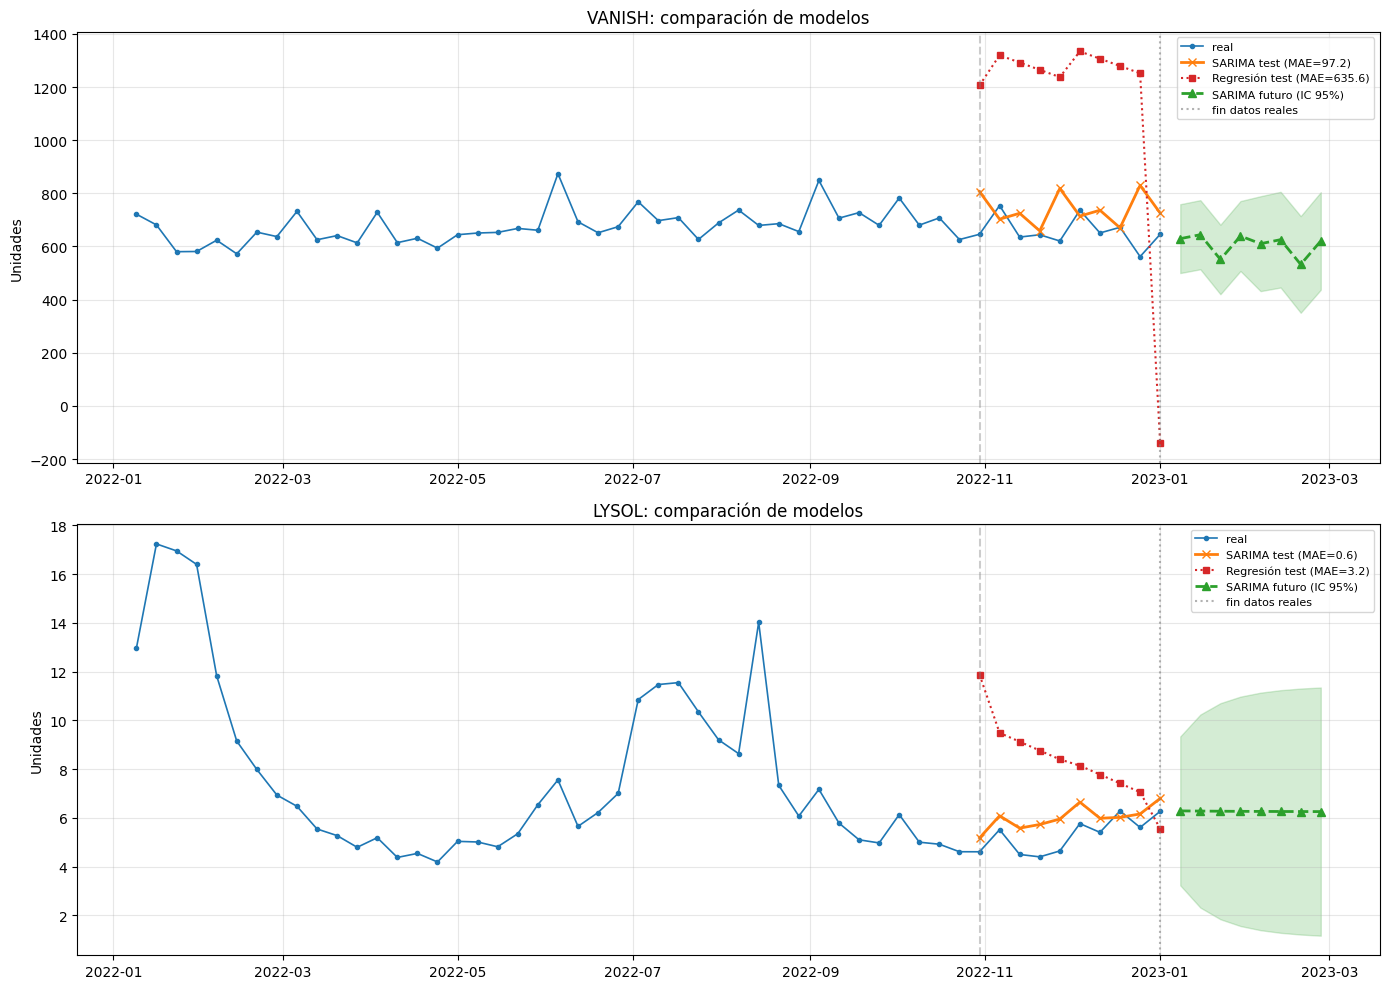

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)

for ax, (marca, r) in zip(axes, resultados.items()):
    s = series_modelo[marca]
    ax.plot(s.index, s.values, label="real", color="C0", marker="o", ms=3, lw=1.2)

    if "pred_sarima" in r:
        ax.plot(r["pred_sarima"].index, r["pred_sarima"].values,label=f"SARIMA test (MAE={r['mae_sarima']:.1f})",color="C1", marker="x", ms=6, lw=2)

    ax.plot(r["pred"].index, r["pred"].values,label=f"Regresión test (MAE={r['mae']:.1f})",color="C3", marker="s", ms=4, lw=1.5, ls=":")

    if "pred_futuro_sarima" in r:
        pf = r["pred_futuro_sarima"]
        ci = r["conf_int_sarima"]
        ax.plot(pf.index, pf.values, label="SARIMA futuro (IC 95%)",color="C2", marker="^", ms=6, lw=2, ls="--")
        ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1],color="C2", alpha=0.2)

    ax.axvline(s.index[-1], color="gray", ls=":", alpha=.6, label="fin datos reales")
    ax.axvline(r["test"].index[0], color="gray", ls="--", alpha=.4)
    ax.set_title(f"{marca}: comparación de modelos")
    ax.set_ylabel("Unidades")
    ax.legend(fontsize=8, loc="best")
    ax.grid(alpha=.3)

plt.tight_layout()
plt.show()

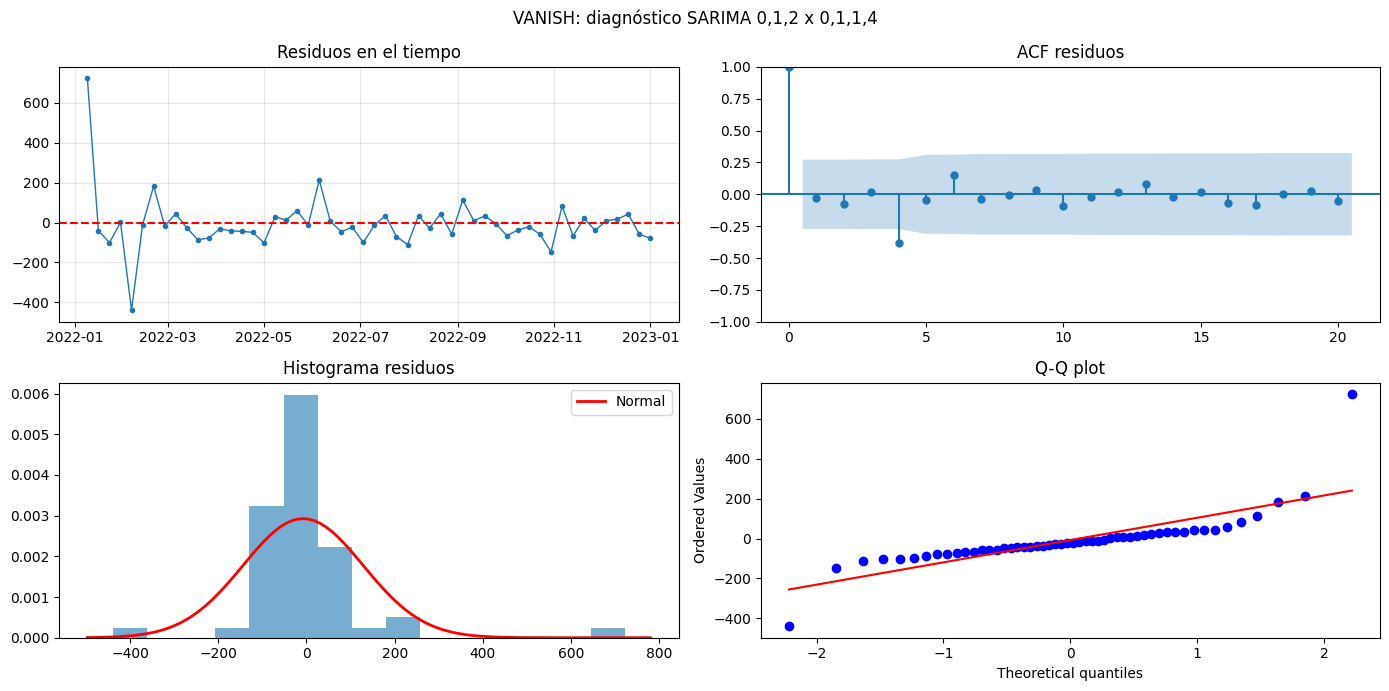

VANISH: Ljung-Box p-value (lag=10) = 0.3484 → residuos NO autocorrelacionados (OK)


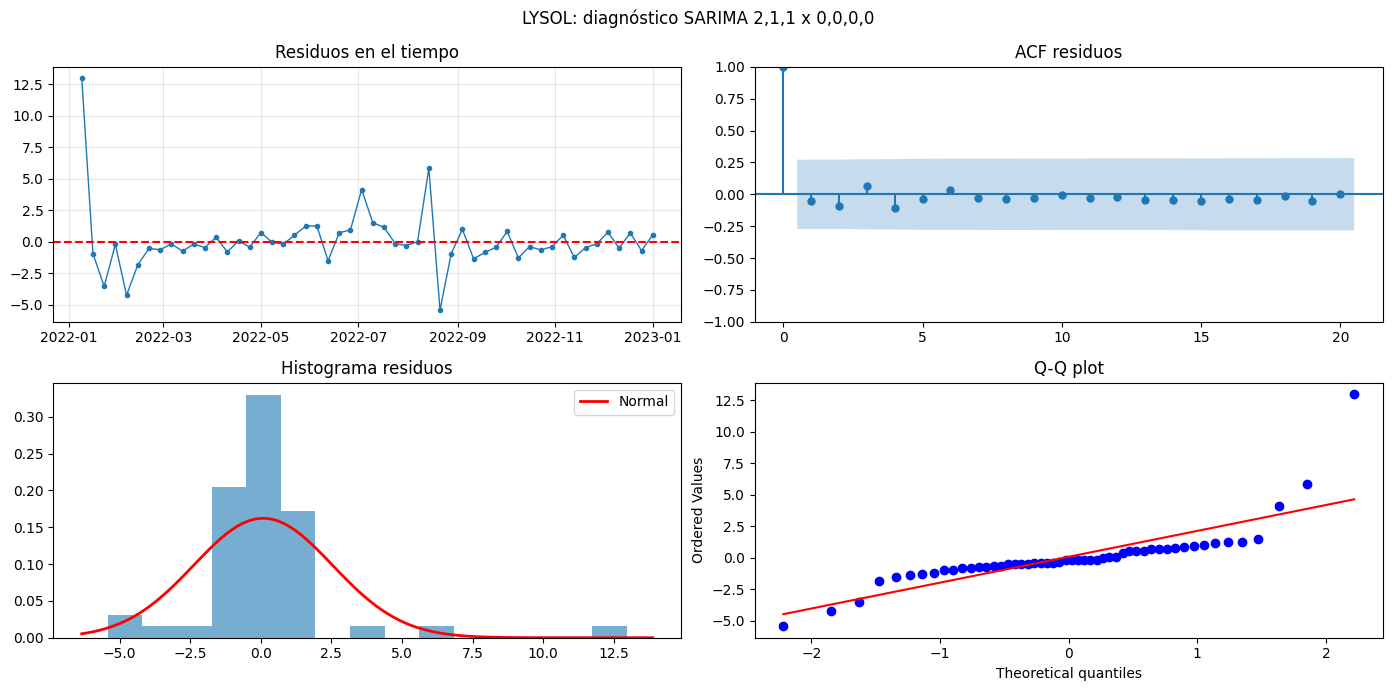

LYSOL: Ljung-Box p-value (lag=10) = 0.9970 → residuos NO autocorrelacionados (OK)


In [18]:
for marca, r in resultados.items():
    if "order_sarima" not in r:
        continue

    p, d, q = r["order_sarima"]
    P, D, Q, s_per = r["seasonal_sarima"]

    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        mod = SARIMAX(series_modelo[marca], order=(p, d, q),seasonal_order=(P, D, Q, s_per),enforce_stationarity=False, enforce_invertibility=False,).fit(disp=False)

    resid = mod.resid
    fig, axes = plt.subplots(2, 2, figsize=(14, 7))
    fig.suptitle(f"{marca}: diagnóstico SARIMA {p},{d},{q} x {P},{D},{Q},{s_per}", fontsize=12)

    axes[0, 0].plot(resid.index, resid.values, marker="o", ms=3, lw=1)
    axes[0, 0].axhline(0, color="red", ls="--")
    axes[0, 0].set_title("Residuos en el tiempo")
    axes[0, 0].grid(alpha=.3)

    plot_acf(resid.dropna(), lags=20, ax=axes[0, 1], title="ACF residuos")

    axes[1, 0].hist(resid.dropna(), bins=15, density=True, alpha=0.6, color="C0")
    xmin, xmax = axes[1, 0].get_xlim()
    xx = np.linspace(xmin, xmax, 100)
    axes[1, 0].plot(xx, stats.norm.pdf(xx, resid.mean(), resid.std()),"r-", lw=2, label="Normal")
    axes[1, 0].set_title("Histograma residuos")
    axes[1, 0].legend()

    stats.probplot(resid.dropna(), dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title("Q-Q plot")

    plt.tight_layout()
    plt.show()

    lb = acorr_ljungbox(resid.dropna(), lags=[10], return_df=True)
    print(f"{marca}: Ljung-Box p-value (lag=10) = {lb['lb_pvalue'].iloc[0]:.4f} "
          f"→ {'residuos NO autocorrelacionados (OK)' if lb['lb_pvalue'].iloc[0] > 0.05 else 'residuos autocorrelacionados (revisar)'}")

In [19]:
print("Resumen de Resultados")

resumen_final = pd.DataFrame({
    marca: {
        "SARIMA order":      str(r.get("order_sarima", "-")),
        "SARIMA seasonal":   str(r.get("seasonal_sarima", "-")),
        "LjungBox p":        r.get("ljungbox_p", np.nan),
        "MAE SARIMA":        r.get("mae_sarima", np.nan),
        "MAPE SARIMA %":     r.get("mape_sarima", np.nan),
        "MAE Regresión":     r["mae"],
        "MAPE Regresión %":  r["mape"],
        "MAE Baseline":      r["mae_b"],
        "MAPE Baseline %":   r["mape_b"],
    }
    for marca, r in resultados.items()}).T.round(2)

print(resumen_final.to_string())
print()

print("Mejora de Sarima sobre la regresión")

for marca, r in resultados.items():
    if "mae_sarima" not in r:
        continue
    reduccion_mae  = (r["mae"]   - r["mae_sarima"])  / r["mae"]   * 100
    reduccion_mape = (r["mape"]  - r["mape_sarima"]) / r["mape"]  * 100
    print(f"{marca}:")
    print(f"  Reducción de MAE  : {reduccion_mae:6.2f}%  "
          f"({r['mae']:.2f} → {r['mae_sarima']:.2f})")
    print(f"  Reducción de MAPE : {reduccion_mape:6.2f}%  "
          f"({r['mape']:.2f}% → {r['mape_sarima']:.2f}%)")
    if "mae_b" in r:
        vs_base = (r["mae_sarima"] - r["mae_b"]) / r["mae_b"] * 100
        estado  = "MEJOR" if vs_base < 0 else "PEOR"
        print(f"  vs Baseline naive : SARIMA es {estado} por {abs(vs_base):.2f}%  "
              f"(SARIMA MAE={r['mae_sarima']:.2f} vs Baseline MAE={r['mae_b']:.2f})")
    print()


print("Amplitud de los Intervalos de Confianza")

for marca, r in resultados.items():
    if "conf_int_sarima" not in r:
        continue
    ci = r["conf_int_sarima"]
    ancho = (ci.iloc[:, 1] - ci.iloc[:, 0])
    print(f"{marca}:")
    print(f"  Ancho promedio IC : {ancho.mean():.2f} unidades")
    print(f"  Ancho mínimo IC   : {ancho.min():.2f}")
    print(f"  Ancho máximo IC   : {ancho.max():.2f}")
    print(f"  Amplitud relativa : {ancho.mean() / r['pred_futuro_sarima'].mean() * 100:.2f}% "
          f"de la predicción media")

Resumen de Resultados
       SARIMA order SARIMA seasonal LjungBox p MAE SARIMA MAPE SARIMA % MAE Regresión MAPE Regresión % MAE Baseline MAPE Baseline %
VANISH    (0, 1, 2)    (0, 1, 1, 4)   0.348398  97.154979     15.643996    635.637234        97.759237    39.049061        5.776355
LYSOL     (2, 1, 1)    (0, 0, 0, 0)   0.996952   0.551221     11.387817      3.204352        65.358235      1.28734       22.469815

Mejora de Sarima sobre la regresión
VANISH:
  Reducción de MAE  :  84.72%  (635.64 → 97.15)
  Reducción de MAPE :  84.00%  (97.76% → 15.64%)
  vs Baseline naive : SARIMA es PEOR por 148.80%  (SARIMA MAE=97.15 vs Baseline MAE=39.05)

LYSOL:
  Reducción de MAE  :  82.80%  (3.20 → 0.55)
  Reducción de MAPE :  82.58%  (65.36% → 11.39%)
  vs Baseline naive : SARIMA es MEJOR por 57.18%  (SARIMA MAE=0.55 vs Baseline MAE=1.29)

Amplitud de los Intervalos de Confianza
VANISH:
  Ancho promedio IC : 311.43 unidades
  Ancho mínimo IC   : 259.05
  Ancho máximo IC   : 367.19
  Amplitud re